In [1]:
import yfinance as yf
import pandas_datareader.data as web
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score
import pandas as pd 


In [2]:
sp500 = yf.Ticker("^GSPC")
sp500

yfinance.Ticker object <^GSPC>

In [3]:
sp500 = sp500.history(period="max")
sp500

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,0.0,0.0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,0.0,0.0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,0.0,0.0
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
...,...,...,...,...,...,...,...
2026-11-17 00:00:00-05:00,7411.020020,7415.370117,7288.339844,7340.529785,5165100000,0.0,0.0
2026-11-18 00:00:00-05:00,7355.689941,7367.680176,7285.759766,7323.629883,5388180000,0.0,0.0
2026-11-19 00:00:00-05:00,7389.259766,7415.640137,7173.629883,7175.830078,5692800000,0.0,0.0


In [4]:
sp500.index

DatetimeIndex(['1927-12-30 00:00:00-05:00', '1928-01-03 00:00:00-05:00',
               '1928-01-04 00:00:00-05:00', '1928-01-05 00:00:00-05:00',
               '1928-01-06 00:00:00-05:00', '1928-01-09 00:00:00-05:00',
               '1928-01-10 00:00:00-05:00', '1928-01-11 00:00:00-05:00',
               '1928-01-12 00:00:00-05:00', '1928-01-13 00:00:00-05:00',
               ...
               '2026-11-10 00:00:00-05:00', '2026-11-11 00:00:00-05:00',
               '2026-11-12 00:00:00-05:00', '2026-11-13 00:00:00-05:00',
               '2026-11-16 00:00:00-05:00', '2026-11-17 00:00:00-05:00',
               '2026-11-18 00:00:00-05:00', '2026-11-19 00:00:00-05:00',
               '2026-11-20 00:00:00-05:00', '2026-11-23 00:00:00-05:00'],
              dtype='datetime64[s, America/New_York]', name='Date',
              length=24842, freq=None)

<Axes: xlabel='Date'>

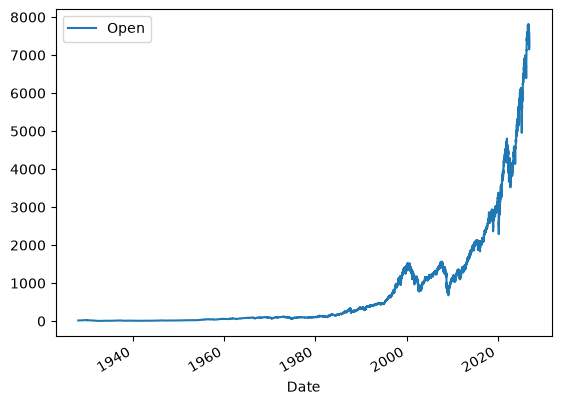

In [5]:
sp500.plot.line(y="Open", use_index=True)

In [6]:
del sp500["Dividends"]
del sp500["Stock Splits"]


In [7]:
sp500["Tommorow"] = sp500["Close"].shift(-1)

In [8]:
sp500

,Open,High,Low,Close,Volume,Tommorow
Date,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.760000
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,17.719999
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,17.549999
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,17.660000
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.500000
...,...,...,...,...,...,...
2026-11-17 00:00:00-05:00,7411.020020,7415.370117,7288.339844,7340.529785,5165100000,7323.629883
2026-11-18 00:00:00-05:00,7355.689941,7367.680176,7285.759766,7323.629883,5388180000,7175.830078
2026-11-19 00:00:00-05:00,7389.259766,7415.640137,7173.629883,7175.830078,5692800000,6910.390137


In [9]:
sp500["Target"] = (sp500["Tommorow"] > sp500["Close"]).astype(int)

In [10]:
sp500

,Open,High,Low,Close,Volume,Tommorow,Target
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.760000,1
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,17.719999,0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,17.549999,0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,17.660000,1
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.500000,0
...,...,...,...,...,...,...,...
2026-11-17 00:00:00-05:00,7411.020020,7415.370117,7288.339844,7340.529785,5165100000,7323.629883,0
2026-11-18 00:00:00-05:00,7355.689941,7367.680176,7285.759766,7323.629883,5388180000,7175.830078,0
2026-11-19 00:00:00-05:00,7389.259766,7415.640137,7173.629883,7175.830078,5692800000,6910.390137,0


In [11]:
model = RandomForestClassifier(n_estimators=500, min_samples_split=100, random_state=1, n_jobs=-2)

train = sp500.iloc[:-100]
test = sp500.iloc[-100:]

predictors = ["Close", "Volume", "Open", "High", "Low"]
model.fit(train[predictors], train["Target"])


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

In [12]:
preds = model.predict(test[predictors])
preds = pd.Series(preds, index=test.index)
preds

Date
2026-07-06 00:00:00-04:00    1
2026-07-07 00:00:00-04:00    1
2026-07-08 00:00:00-04:00    1
2026-07-09 00:00:00-04:00    1
2026-07-10 00:00:00-04:00    1
                            ..
2026-11-17 00:00:00-05:00    1
2026-11-18 00:00:00-05:00    1
2026-11-19 00:00:00-05:00    1
2026-11-20 00:00:00-05:00    1
2026-11-23 00:00:00-05:00    1
Length: 100, dtype: int64

In [13]:
precision_score(test["Target"], preds)

0.42105263157894735

<Axes: xlabel='Date'>

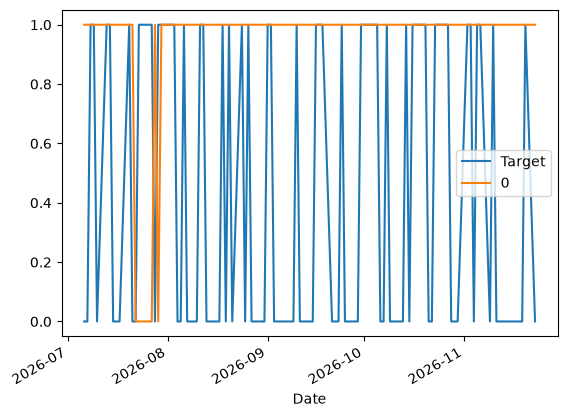

In [14]:
combined = pd.concat([test["Target"], preds], axis=1)
combined.plot()


In [15]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict(test[predictors])
    preds = pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis=1)
    return combined


In [16]:
def backprop(data, model, predictors, start=15750, step=250):
    all_preds = []
    for i in range(start, data.shape[0], step):
        train = data.iloc[0:i].copy()
        test = data.iloc[i:(i+step)].copy()
        predictions = predict(train, test, predictors, model)
        all_preds.append(predictions)
    return pd.concat(all_preds)

In [17]:
predictions = backprop(sp500, model, predictors)

In [18]:
predictions["Predictions"].value_counts()

Predictions
0    6121
1    2971
Name: count, dtype: int64

In [19]:
precision_score(predictions["Target"], predictions["Predictions"])

0.5270952541231908

In [20]:
predictions["Target"].value_counts() / predictions.shape[0]

Target
1    0.536296
0    0.463704
Name: count, dtype: float64

In [ ]:
horizons = [2, 5, 60, 250, 1000]
new_predictors = []

for horizon in horizons:
    rolling_averages = sp500.rolling(horizon).mean()

    ratio_column = f"Close_Ratio_{horizon}"
    sp500[ratio_column] = sp500["Close"] / rolling_averages["Close"]

    trend_column = f"Trend_{horizon}"
    sp500[trend_column] = sp500.shift(1).rolling(horizon).sum()["Target"]